<a href="https://colab.research.google.com/github/Rageel-28/244107020136-Machine-Learning/blob/main/JS08/JS08_02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS08 - Hierarchical Clustering
## Lab 2 - HDBSCAN

HDBSCAN (*Hierarchical Density-Based Spatial Clustering of Applications with Noise*) adalah pengembangan DBSCAN yang digabungkan dengan klasterisasi hierarkis. Berbeda dengan DBSCAN, HDBSCAN **tidak bergantung pada satu nilai `eps` global**, sehingga lebih tahan terhadap perbedaan skala data dan mampu menemukan *cluster* dengan **kepadatan berbeda**.

Parameter yang menjadi fokus: `min_cluster_size`, `min_samples`, dan `cut_distance`.

## Langkah 0 - Instalasi dan Import Library

In [1]:
# Paket hdbscan tidak termasuk scikit-learn. Pasang otomatis jika belum ada (Google Colab / lokal).
try:
    import hdbscan
except ImportError:
    import sys, subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'hdbscan'])
    import hdbscan

print('hdbscan siap dipakai')

hdbscan siap dipakai


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs
from sklearn.cluster import DBSCAN

## Langkah 1 - Fungsi Bantu untuk Plotting

Fungsi untuk memplot hasil klasterisasi: setiap *cluster* diberi warna sendiri, sedangkan titik ***noise*** (label −1) digambar **hitam**.

In [3]:
def plot_clusters(X, labels, title='', ax=None, probabilities=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5))

    palette = sns.color_palette('deep', max(int(labels.max()) + 1, 1))
    for lab in sorted(set(labels)):
        mask = labels == lab
        if lab == -1:
            ax.scatter(X[mask, 0], X[mask, 1], c='black', s=20, label='noise')
        else:
            alpha = 0.9 if probabilities is None else None
            ax.scatter(X[mask, 0], X[mask, 1], color=palette[lab], s=25, alpha=alpha, label=f'cluster {lab}')
    ax.set_title(title)
    ax.legend(fontsize=8)
    return ax

## Langkah 2 - Membuat Data Sintetis

Tiga kelompok data Gaussian (`make_blobs`) dengan sebaran (*spread*) yang berbeda.

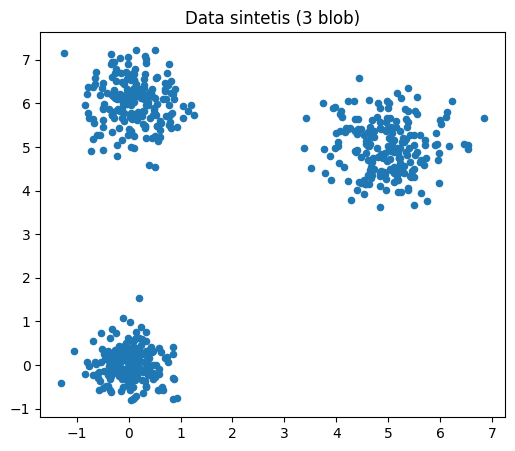

In [4]:
centers = [[0, 0], [5, 5], [0, 6]]
X, y_true = make_blobs(n_samples=600, centers=centers, cluster_std=[0.4, 0.6, 0.5], random_state=42)

plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], s=20)
plt.title('Data sintetis (3 blob)')
plt.show()

## Langkah 3 - Sensitivitas DBSCAN terhadap Skala Data

DBSCAN memakai `eps` yang bersifat **mutlak**. Jika data diperbesar/diperkecil skalanya, `eps` yang sama menjadi tidak cocok.

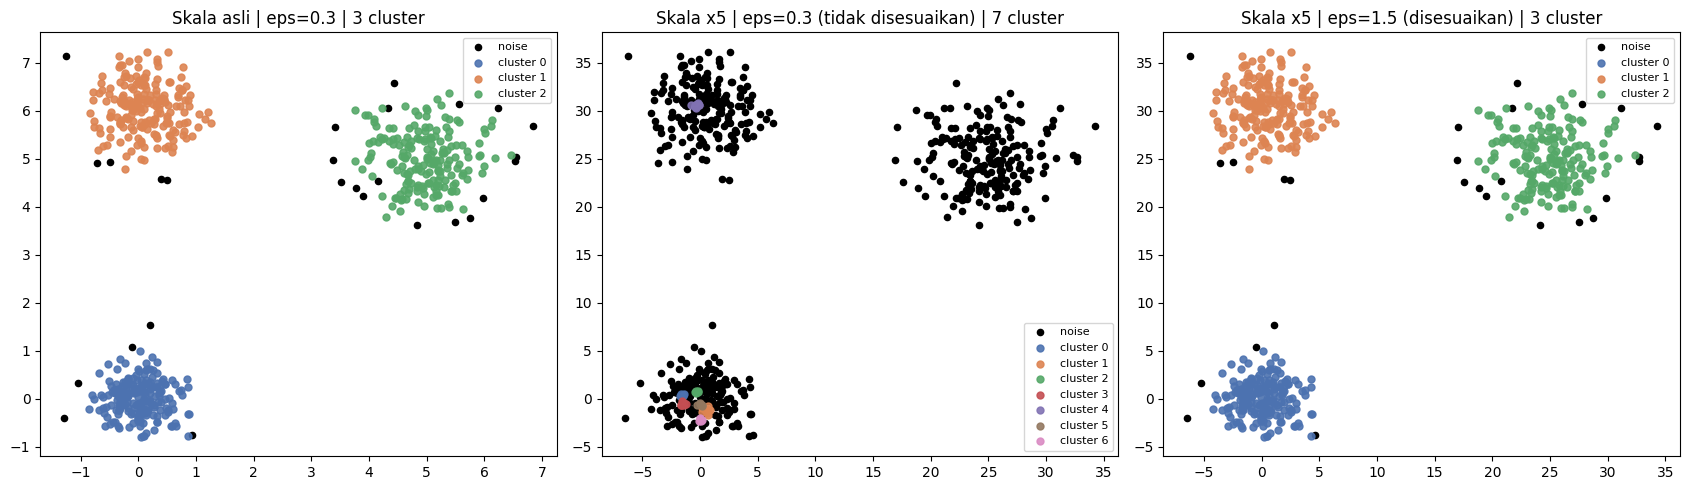

Noise (a) skala asli, eps=0.3   : 27 titik
Noise (b) skala x5,  eps=0.3   : 553 titik
Noise (c) skala x5,  eps=1.5   : 27 titik


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5))

# (a) skala asli, eps = 0.3
lab_a = DBSCAN(eps=0.3, min_samples=5).fit_predict(X)
plot_clusters(X, lab_a, f'Skala asli | eps=0.3 | {len(set(lab_a)) - (1 if -1 in lab_a else 0)} cluster', ax[0])

# (b) data diperbesar 5x, eps tetap 0.3 -> tidak cocok lagi
X_big = X * 5
lab_b = DBSCAN(eps=0.3, min_samples=5).fit_predict(X_big)
plot_clusters(X_big, lab_b, f'Skala x5 | eps=0.3 (tidak disesuaikan) | {len(set(lab_b)) - (1 if -1 in lab_b else 0)} cluster', ax[1])

# (c) data diperbesar 5x, eps disesuaikan menjadi 0.3 x 5 = 1.5
lab_c = DBSCAN(eps=1.5, min_samples=5).fit_predict(X_big)
plot_clusters(X_big, lab_c, f'Skala x5 | eps=1.5 (disesuaikan) | {len(set(lab_c)) - (1 if -1 in lab_c else 0)} cluster', ax[2])

plt.tight_layout()
plt.show()

print(f'Noise (a) skala asli, eps=0.3   : {(lab_a == -1).sum()} titik')
print(f'Noise (b) skala x5,  eps=0.3   : {(lab_b == -1).sum()} titik')
print(f'Noise (c) skala x5,  eps=1.5   : {(lab_c == -1).sum()} titik')

**Kesimpulan:** pada skala yang berbeda, `eps` yang sama tidak lagi sesuai (sebagian besar titik menjadi *noise* atau terpecah), dan harus disesuaikan secara manual. Inilah kelemahan DBSCAN.

## Langkah 4 - HDBSCAN pada Data dengan Skala Berbeda

HDBSCAN diterapkan pada data skala asli dan data yang diperbesar 5×, **tanpa mengatur jarak `eps`**.

Skala asli : 3 cluster, noise = 0 titik
Skala x5   : 3 cluster, noise = 0 titik


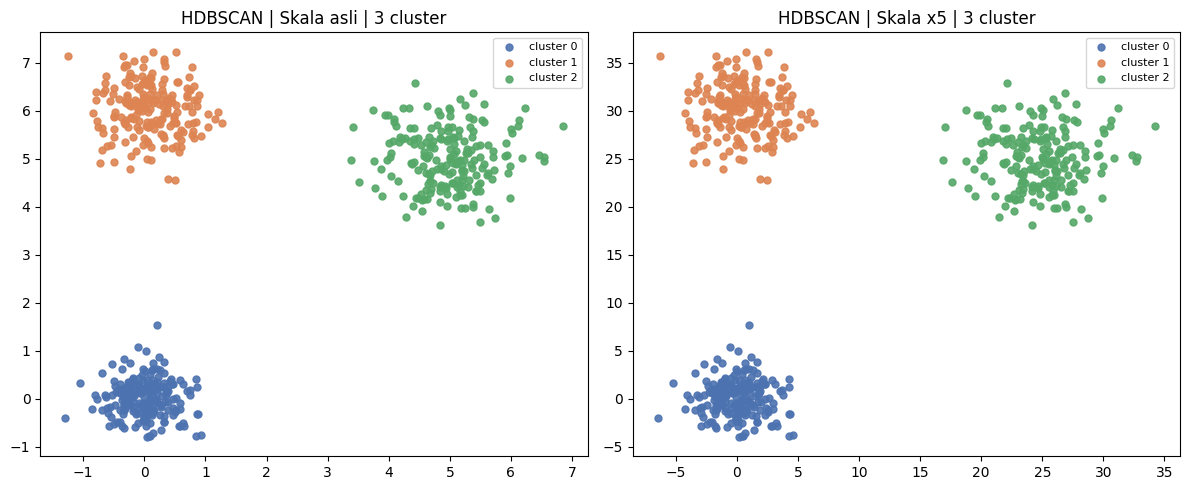

In [6]:
import hdbscan

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

for a, data, nama in [(ax[0], X, 'Skala asli'), (ax[1], X_big, 'Skala x5')]:
    model = hdbscan.HDBSCAN(min_cluster_size=15)
    lab = model.fit_predict(data)
    n_cl = len(set(lab)) - (1 if -1 in lab else 0)
    plot_clusters(data, lab, f'HDBSCAN | {nama} | {n_cl} cluster', a)
    print(f'{nama:<11}: {n_cl} cluster, noise = {(lab == -1).sum()} titik')

plt.tight_layout()
plt.show()

HDBSCAN menghasilkan jumlah *cluster* yang sama pada kedua skala **tanpa menyesuaikan parameter jarak**.

## Langkah 5 - Data dengan Kepadatan Berbeda (Multiscale)

Kini data dengan *cluster* yang kepadatannya sangat berbeda: satu sangat padat, satu sedang, dan satu sangat renggang. Satu nilai `eps` global sulit mengakomodasi ketiganya.

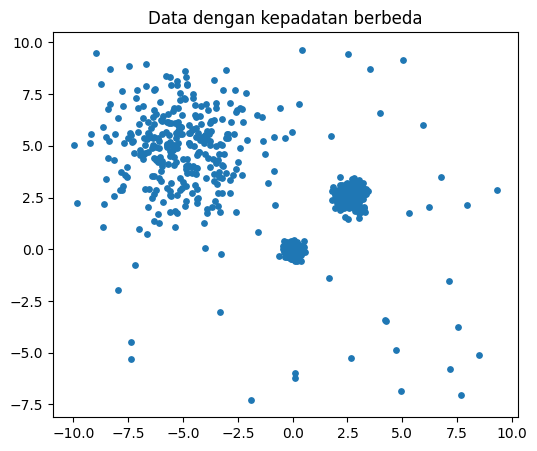

In [7]:
# 3 cluster dengan kepadatan sangat berbeda (std 0.2 / 0.35 / 1.8) + 40 titik latar acak
centers_ms = [[0, 0], [2.6, 2.6], [-5, 5]]
X_blob, _ = make_blobs(n_samples=[300, 300, 300], centers=centers_ms,
                       cluster_std=[0.2, 0.35, 1.8], random_state=7)
rng = np.random.default_rng(3)
X_ms = np.vstack([X_blob, rng.uniform(-9, 10, size=(40, 2))])

plt.figure(figsize=(6, 5))
plt.scatter(X_ms[:, 0], X_ms[:, 1], s=15)
plt.title('Data dengan kepadatan berbeda')
plt.show()

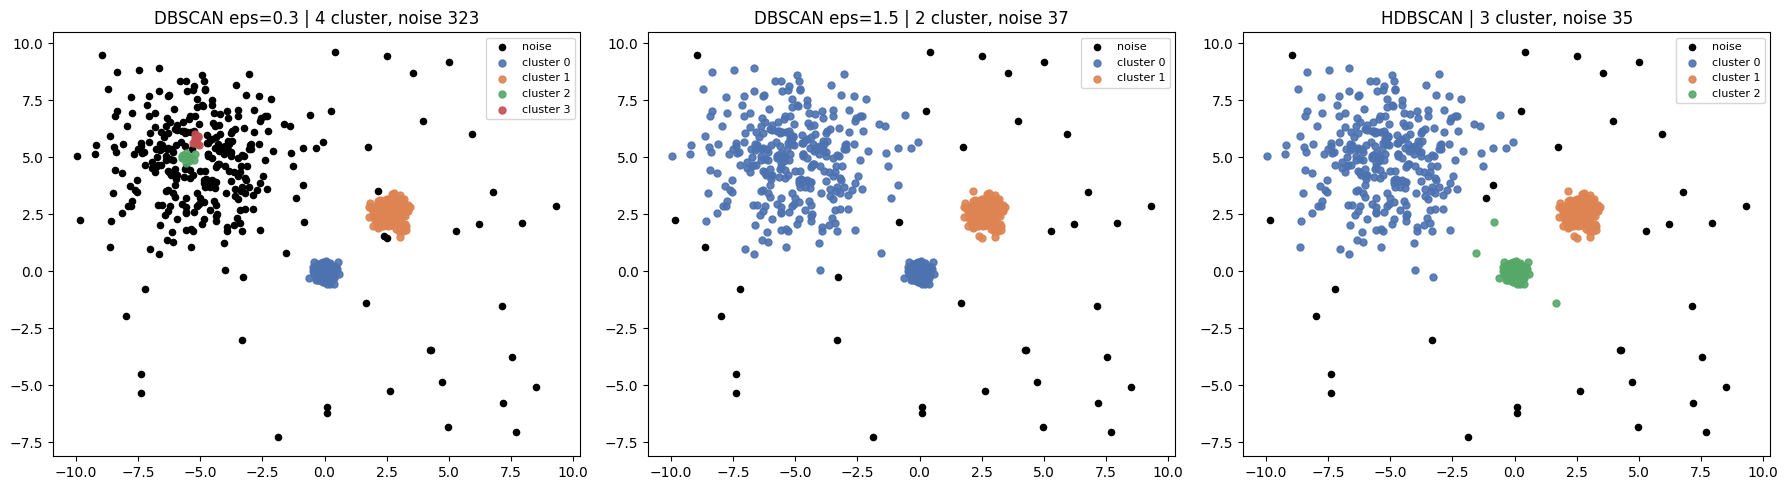

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

# DBSCAN eps kecil -> cluster renggang menjadi noise
l1 = DBSCAN(eps=0.3, min_samples=10).fit_predict(X_ms)
plot_clusters(X_ms, l1, f'DBSCAN eps=0.3 | {len(set(l1)) - (1 if -1 in l1 else 0)} cluster, noise {(l1 == -1).sum()}', ax[0])

# DBSCAN eps besar -> cluster berdekatan menyatu
l2 = DBSCAN(eps=1.5, min_samples=10).fit_predict(X_ms)
plot_clusters(X_ms, l2, f'DBSCAN eps=1.5 | {len(set(l2)) - (1 if -1 in l2 else 0)} cluster, noise {(l2 == -1).sum()}', ax[1])

# HDBSCAN
clusterer = hdbscan.HDBSCAN(min_cluster_size=30)
l3 = clusterer.fit_predict(X_ms)
plot_clusters(X_ms, l3, f'HDBSCAN | {len(set(l3)) - (1 if -1 in l3 else 0)} cluster, noise {(l3 == -1).sum()}', ax[2])

plt.tight_layout()
plt.show()

## Langkah 6 - Probabilitas Keanggotaan *Cluster*

HDBSCAN memberikan **probabilitas keanggotaan** (`probabilities_`) untuk setiap titik: titik di pusat *cluster* bernilai mendekati 1, titik di pinggir lebih rendah, dan *noise* bernilai 0.

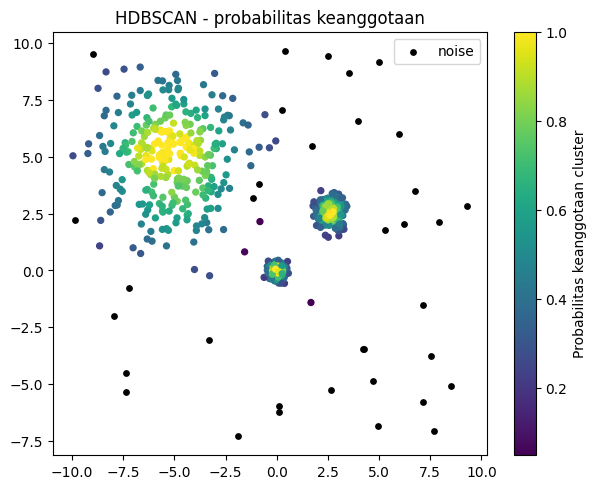

Rata-rata probabilitas (non-noise): 0.726
Probabilitas minimum (non-noise)  : 0.049


In [9]:
probs = clusterer.probabilities_

plt.figure(figsize=(7, 5.5))
mask_noise = clusterer.labels_ == -1
plt.scatter(X_ms[mask_noise, 0], X_ms[mask_noise, 1], c='black', s=15, label='noise')
sc = plt.scatter(X_ms[~mask_noise, 0], X_ms[~mask_noise, 1], c=probs[~mask_noise], cmap='viridis', s=18)
plt.colorbar(sc, label='Probabilitas keanggotaan cluster')
plt.title('HDBSCAN - probabilitas keanggotaan')
plt.legend()
plt.show()

print(f'Rata-rata probabilitas (non-noise): {probs[~mask_noise].mean():.3f}')
print(f'Probabilitas minimum (non-noise)  : {probs[~mask_noise].min():.3f}')

### Analisis

Pada data kepadatan berbeda di atas (angka dapat diperiksa pada judul grafik): DBSCAN dengan `eps=0.3` hanya cocok untuk *cluster* yang padat, sehingga *cluster* yang renggang berubah menjadi *noise* dan *cluster* padat terpecah. DBSCAN dengan `eps=1.5` sebaliknya menggabungkan dua *cluster* yang berdekatan menjadi satu. HDBSCAN menemukan 3 *cluster* tanpa mengatur `eps`.

| Aspek | DBSCAN | HDBSCAN |
|---|---|---|
| Parameter jarak | Perlu `eps` global yang peka terhadap skala | Tidak memerlukan `eps` |
| Kepadatan berbeda | Satu `eps` sulit cocok untuk semua *cluster* | Mampu menemukan *cluster* berbeda kepadatan |
| Keluaran | Label saja | Label + probabilitas keanggotaan |

HDBSCAN tetap memiliki parameter: `min_cluster_size` (ukuran minimum *cluster*) dan `min_samples` (seberapa konservatif titik dianggap *noise*). Pengaruh keduanya dieksplorasi pada Lab 3.